In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt 
import glob
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import glob
import os
from shapely.geometry import LineString, MultiLineString
warnings.filterwarnings('ignore', category=RuntimeWarning)

In [2]:
NWM3_retrospective_1979_2023 = pd.read_parquet("/bighome/hdagne1/NeuralNGEN/data/streamflow/NWMv3_retro_1979_2023.parquet")
NWM3_retrospective_1979_2023

USGS_streamflow_1979_2023 = pd.read_parquet("/bighome/hdagne1/NeuralNGEN/data/streamflow/USGS_streamflow_1979_2023.parquet")
NWM3_retrospective_1979_2023
USGS_streamflow_1979_2023.columns = USGS_streamflow_1979_2023.columns.astype(str).map(lambda x: '0' + x if not x.startswith('0') else x)
NWM3_retrospective_1979_2023.columns = NWM3_retrospective_1979_2023.columns.astype(str).map(lambda x: '0' + x if not x.startswith('0') else x)


common = USGS_streamflow_1979_2023.columns.intersection(NWM3_retrospective_1979_2023.columns, sort=False)
print(f"common: {len(common)} | USGS not in NWM: "
      f"{len(USGS_streamflow_1979_2023.columns) - len(common)}")

NWM3_retrospective_1979_2023 = NWM3_retrospective_1979_2023[common]
USGS_streamflow_1979_2023 = USGS_streamflow_1979_2023[common]
USGS_streamflow_1979_2023

common: 3547 | USGS not in NWM: 0


,01010000,01010500,01011000,01013500,01014000,01015800,01017000,01018500,01019000,01021000,...,014339000,014357500,014359000,014361500,014362000,014366000,014369500,014372300,014377100,014400000
Time,,,,,,,,,,,,,,,,,,,,,
2000-01-01,18.689088,39.926688,24.069280,30.582144,113.267200,20.104928,36.811840,26.900960,3.624550,67.677152,...,45.873216,1.160989,48.138560,49.554400,5.550093,5.889894,8.523357,74.190016,11.524938,20.161562
2000-01-02,18.405920,39.643520,23.361360,28.599968,110.435520,19.538592,35.396000,26.844326,3.624550,57.199936,...,43.041536,1.132672,45.306880,48.138560,5.521776,5.889894,8.523357,80.419712,11.326720,22.795024
2000-01-03,18.264336,39.360352,24.352448,28.033632,107.603840,19.085523,33.980160,26.844326,3.624550,54.651424,...,42.192032,1.104355,45.306880,47.289056,5.521776,5.833261,8.438406,78.154368,11.156819,22.172054
2000-01-04,22.511856,48.138560,25.485120,27.410662,116.098880,18.462554,32.564320,26.929277,9.372861,59.182112,...,43.607872,1.104355,46.722720,48.421728,5.521776,5.918211,8.579990,87.215744,13.365530,33.980160
2000-01-05,25.201952,56.633600,23.786112,27.099178,124.593920,18.207702,31.714816,23.219776,13.280579,66.544480,...,50.970240,1.076038,53.801920,55.784096,5.521776,5.833261,8.636624,94.011776,14.101766,39.926688
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-01-04,24.182547,43.324704,24.210864,32.847488,123.178080,20.048294,32.564320,26.051456,18.264336,75.889024,...,43.891040,1.061880,51.819744,55.784096,3.143165,4.020986,6.144746,103.073152,18.717405,48.988064
2020-01-05,23.417994,41.908864,24.040963,31.431648,119.780064,19.680176,31.714816,26.023139,18.264336,73.906848,...,43.324704,0.993920,51.253408,56.067264,3.143165,3.936035,6.371280,107.887008,22.625123,57.199936
2020-01-06,22.625123,40.493024,23.786112,30.298976,116.665216,19.312058,30.865312,25.966506,18.264336,70.225664,...,42.475200,0.914633,49.554400,53.235584,3.143165,3.879402,6.144746,106.754336,25.315219,62.580128


# NWM vs USGS KGE distributions accross all basins

NWM raw ID lengths: {8: 2910, 9: 636, 10: 1}
USGS raw ID lengths: {8: 2910, 9: 636, 10: 1}
NWM gages: 3547
USGS gages: 3547
Common gages: 3547 | USGS not in NWM: 0
NWM                    {'01': 517, '02': 439, '03': 333, '04': 198, '05': 325, '06': 351, '07': 261, '08': 273, '09': 213, '10': 110, '11': 181, '12': 139, '13': 97, '14': 109, '42': 1}
USGS                   {'01': 517, '02': 439, '03': 333, '04': 198, '05': 325, '06': 351, '07': 261, '08': 273, '09': 213, '10': 110, '11': 181, '12': 139, '13': 97, '14': 109, '42': 1}
common                 {'01': 517, '02': 439, '03': 333, '04': 198, '05': 325, '06': 351, '07': 261, '08': 273, '09': 213, '10': 110, '11': 181, '12': 139, '13': 97, '14': 109, '42': 1}
(7313, 3547) (7313, 3547) 2000-01-01 00:00:00 2020-01-08 00:00:00
median NWM/USGS ratio across gages: 1.134
(3547, 6)
Gages with valid KGE: 3544
Gages with NaN KGE (zero variance/no overlap): 3
valid KGE              {'01': 517, '02': 438, '03': 333, '04': 198, '05': 325, '06':

/bighome/hdagne1/NeuralNGEN/Figures/NWM_USGS_streamflow_KGE.py:229: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


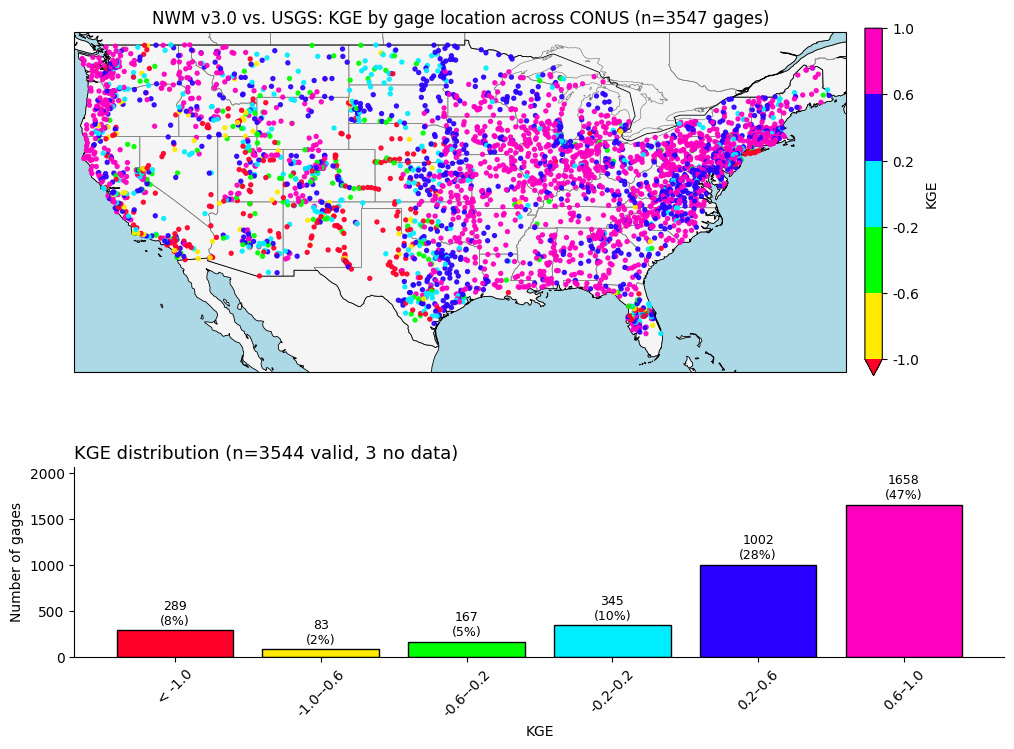

           n_gages        pct
KGE_bin                      
< -1.0         289   8.147730
-1.0–-0.6       83   2.340006
-0.6–-0.2      167   4.708204
-0.2–0.2       345   9.726529
0.2–0.6       1002  28.249225
0.6–1.0       1658  46.743727

Total gages: 3547
No data (NaN KGE): 3


In [3]:
%run /bighome/hdagne1/NeuralNGEN/Figures/NWM_USGS_streamflow_KGE.py

# NWM vs USGS streamflow accross ref and non-ref basins

NWM raw ID lengths: {8: 2910, 9: 636, 10: 1}
USGS raw ID lengths: {8: 2910, 9: 636, 10: 1}
NWM                    {'01': 517, '02': 439, '03': 333, '04': 198, '05': 325, '06': 351, '07': 261, '08': 273, '09': 213, '10': 110, '11': 181, '12': 139, '13': 97, '14': 109, '42': 1}
USGS                   {'01': 517, '02': 439, '03': 333, '04': 198, '05': 325, '06': 351, '07': 261, '08': 273, '09': 213, '10': 110, '11': 181, '12': 139, '13': 97, '14': 109, '42': 1}
common                 {'01': 517, '02': 439, '03': 333, '04': 198, '05': 325, '06': 351, '07': 261, '08': 273, '09': 213, '10': 110, '11': 181, '12': 139, '13': 97, '14': 109, '42': 1}
(7313, 3547) (7313, 3547) 2000-01-01 00:00:00 2020-01-08 00:00:00
median NWM/USGS ratio across gages: 1.134
missing coords         {}
plotted                {'01': 517, '02': 438, '03': 333, '04': 198, '05': 325, '06': 351, '07': 261, '08': 273, '09': 212, '10': 109, '11': 181, '12': 139, '13': 97, '14': 109, '42': 1}


/bighome/hdagne1/NeuralNGEN/Figures/NWM_USGS_streamflow_KGE_ref_non_ref.py:169: DtypeWarning: Columns (2,4,5,6,7,8,9,23,26,27,34,48,49,50,51,52,53,67,68,73,74,75,105,106,107,108,121,122,123,124) have mixed types. Specify dtype option on import or set low_memory=False.
  Master_combined_8776_sites_FINAL = pd.read_csv(
/bighome/hdagne1/NeuralNGEN/Figures/NWM_USGS_streamflow_KGE_ref_non_ref.py:253: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


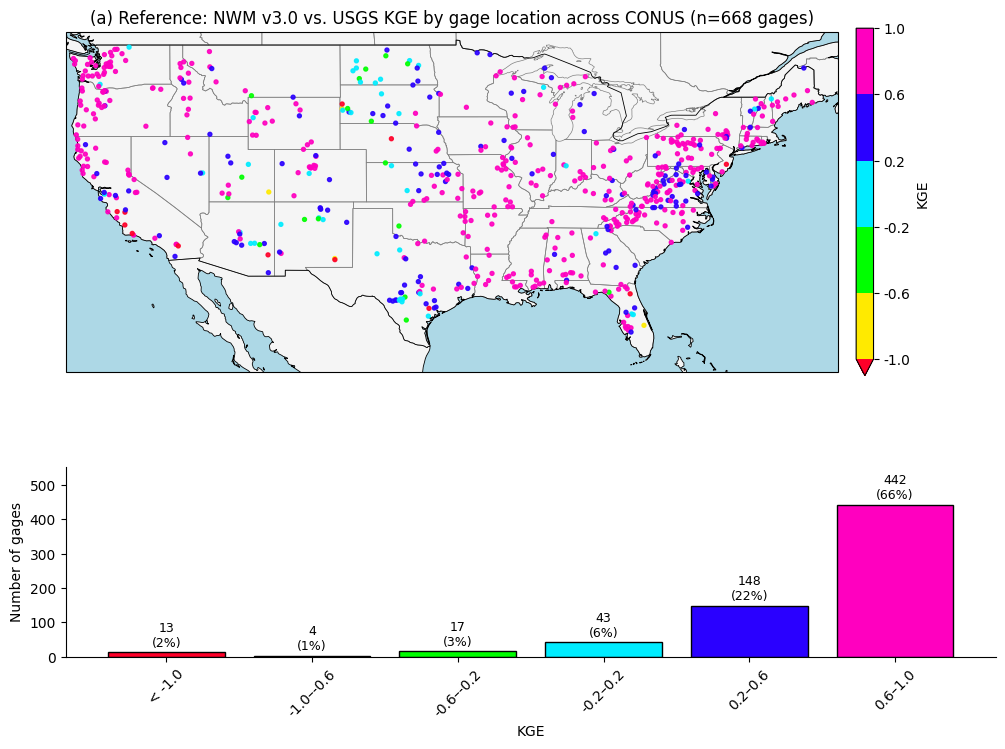

/bighome/hdagne1/NeuralNGEN/Figures/NWM_USGS_streamflow_KGE_ref_non_ref.py:253: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


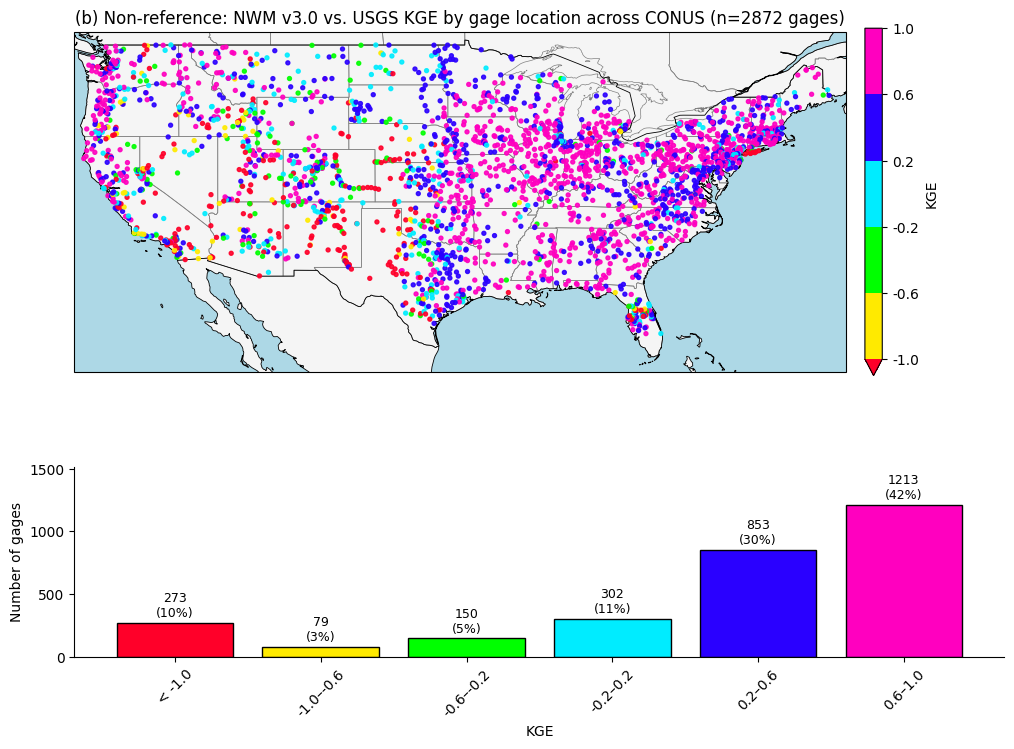

In [4]:
%run /bighome/hdagne1/NeuralNGEN/Figures/NWM_USGS_streamflow_KGE_ref_non_ref.py

# NextGen Hydrofabric v2.2 networks accrros CONUS:

[found] NGIAB copy: /home/hdagne1/.ngiab/hydrofabric/v2.2/conus_nextgen.gpkg
[layers] flowpaths, divides, lakes, hydrolocations, nexus, pois, flowpath-attributes, flowpath-attributes-ml, network, divide-attributes
[read] divides: 831,777 features (9 s)
[read] flowpaths: 828,288 features (6 s)
[filter] flowpaths with order >= 3: 129,675
[read] hydrolocations: 151,469 features (1 s)
[gauges] 18,177
[saved] conus_hydrofabric_v2.2.png (15 s)


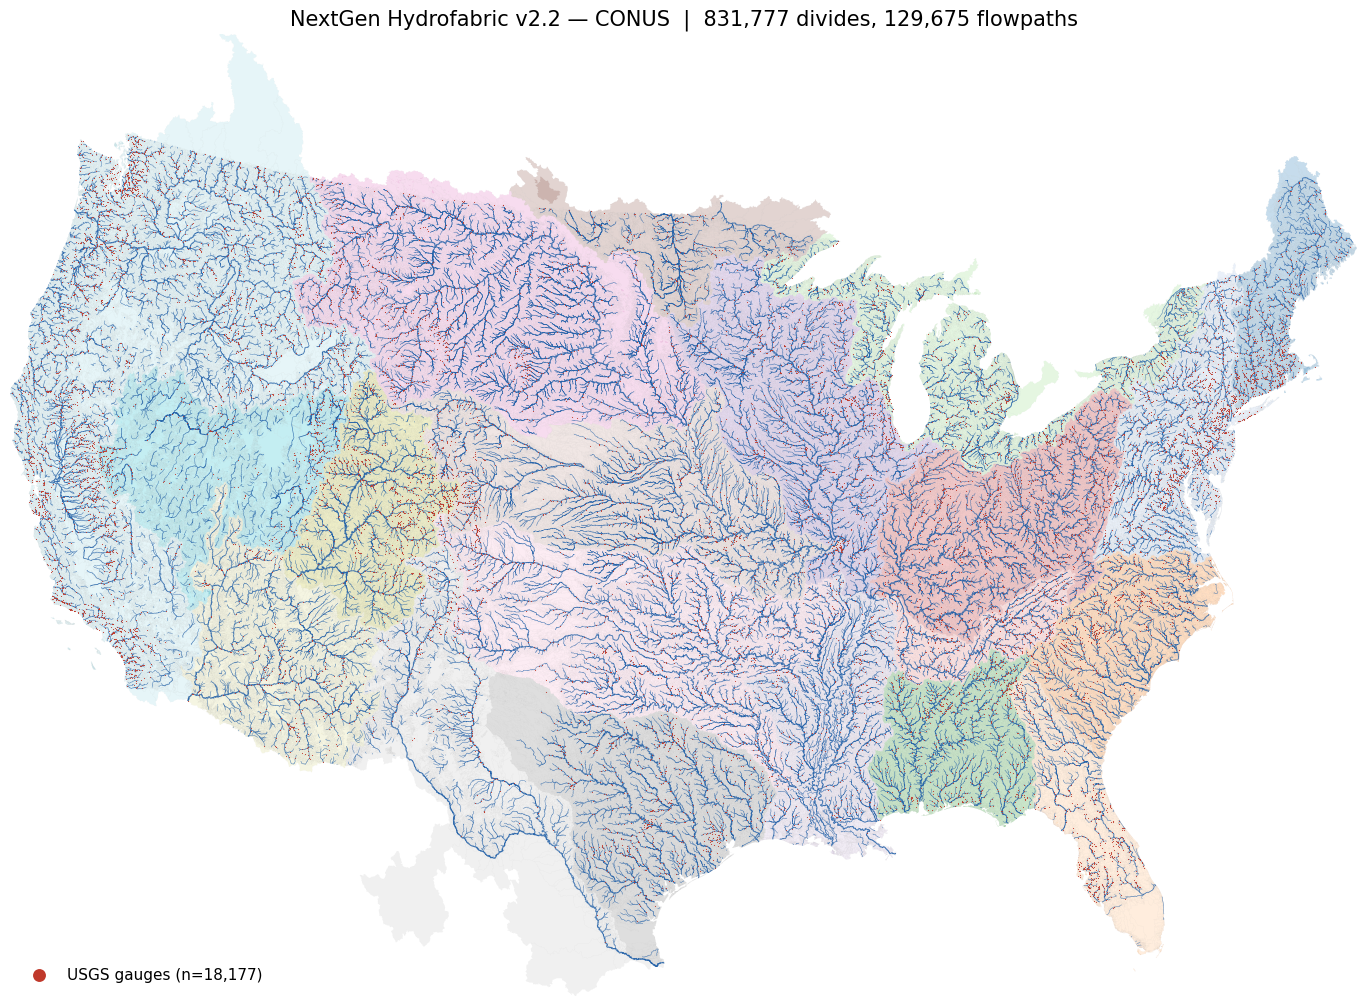

In [5]:
%run /bighome/hdagne1/NeuralNGEN/Figures/nextgen_hydrofabroic_v2_2_map.py

# National Water Model catchments networks accrros CONUS:

[found] /bighome/hdagne1/NeuralNGEN/data/nhdplusv2/NHDPlusNationalData/NHDPlusV21_National_Seamless_Flattened_Lower48.gdb


/bighome/hdagne1/.conda/envs/BUDYKO-dev/lib/python3.10/site-packages/pyogrio/core.py:130: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiLineString' is converted to 'MultiLineString Z'
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
/bighome/hdagne1/.conda/envs/BUDYKO-dev/lib/python3.10/site-packages/pyogrio/core.py:279: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiLineString' is converted to 'MultiLineString Z'
  return ogr_read_info(
/bighome/hdagne1/.conda/envs/BUDYKO-dev/lib/python3.10/contextlib.py:135: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiLineString' is converted to 'MultiLineString Z'
  return next(self.gen)


[read] NHDFlowline_Network: 2,691,339 features (69 s)
[filter] main map: StreamOrde >= 3: 712,701 flowlines
[read] Catchment: 2,647,454 features (170 s)
[inset] NextGen divides in window: 1,243
[simplify] 433 s
[draw] main map 105 s
[saved] conus_nwm_nhdplusv2_catchments.png (30 s)


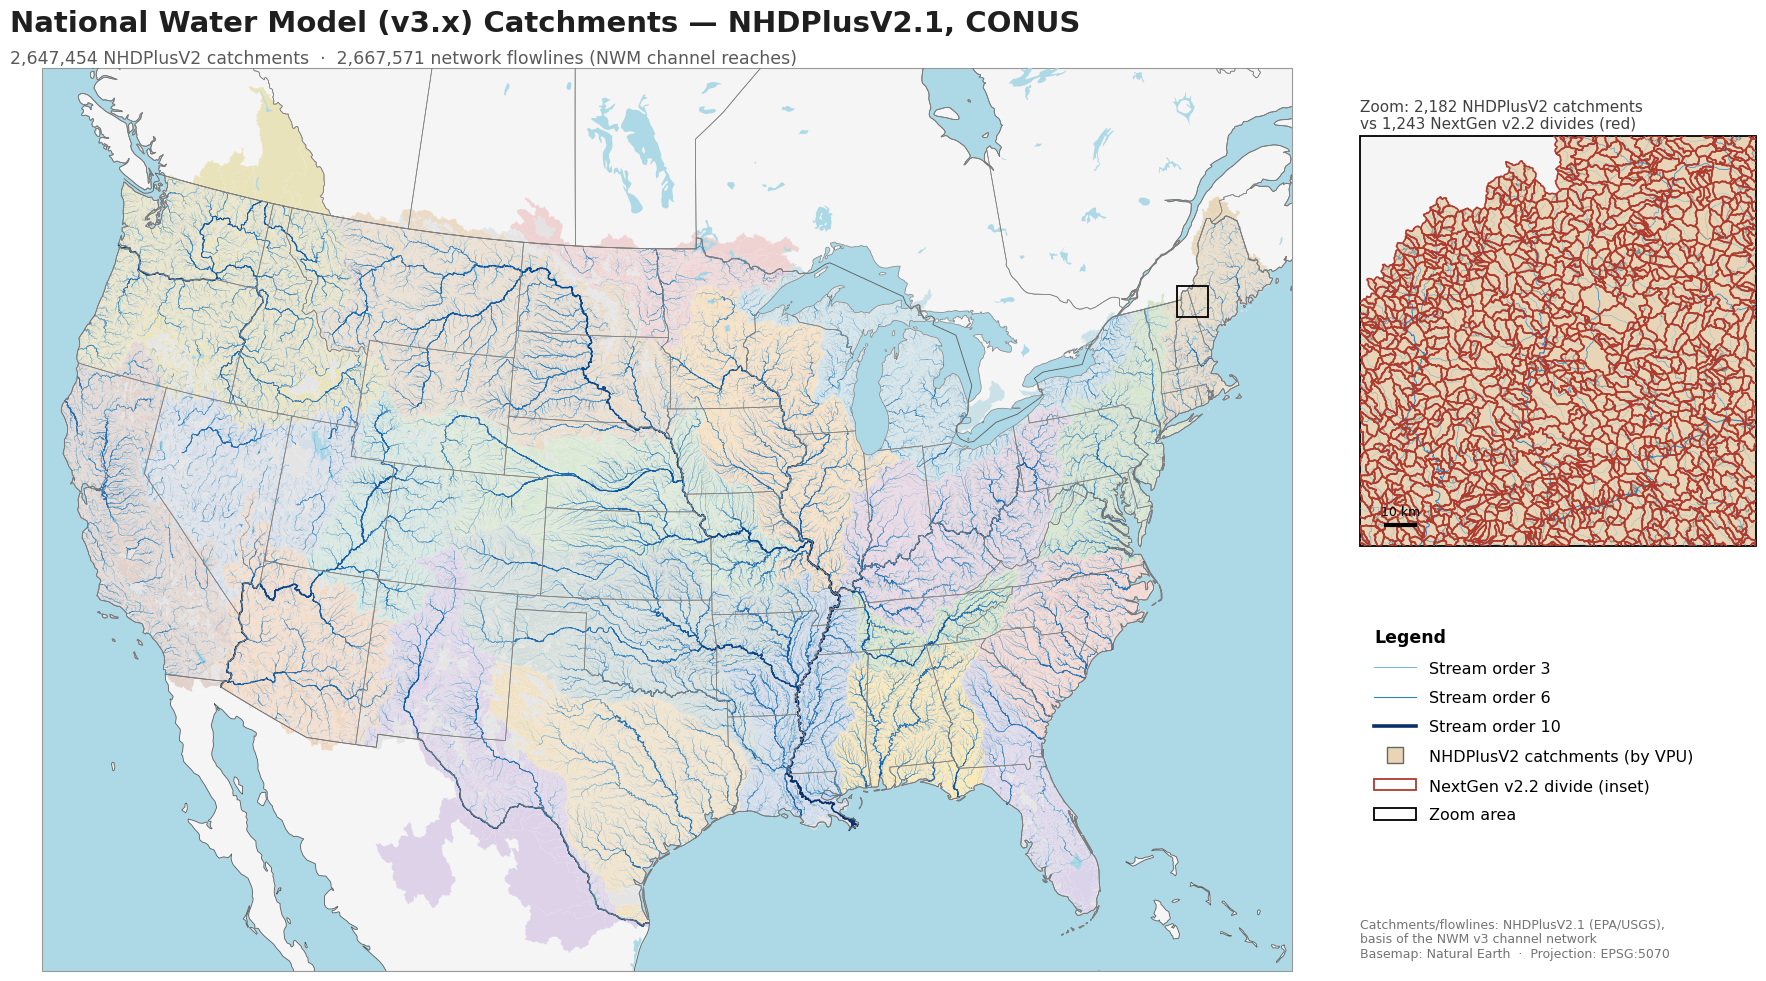

In [6]:
%run /bighome/hdagne1/NeuralNGEN/Figures/map_nwm_cathcments.py

gauges with 4 scenarios + obs: 298


/bighome/hdagne1/.conda/envs/BUDYKO-dev/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/bighome/hdagne1/.conda/envs/BUDYKO-dev/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


gauges in boxplots: 280


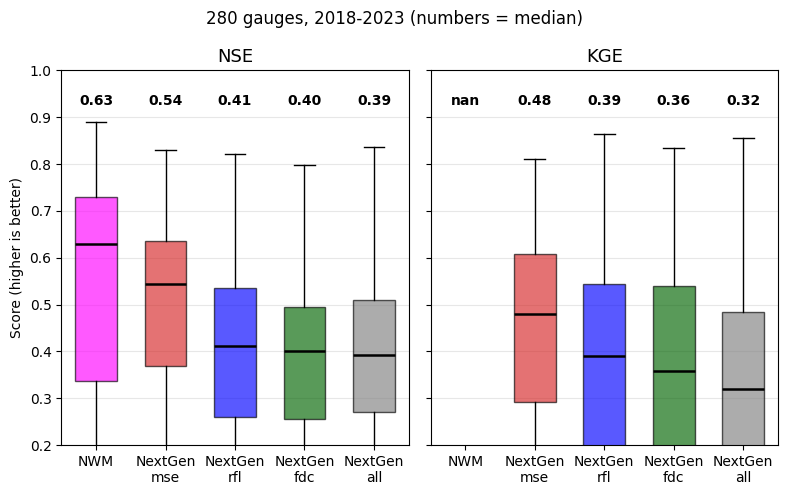

         NSE    KGE
model              
NWM    0.629  0.770
mse    0.544  0.479
rfl    0.412  0.391
fdc    0.401  0.357
all    0.392  0.320


In [1]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
OUT = "/bighome/hdagne1/NeuralNGEN/ngen_boxplots_shifted.png"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
COLORS = {"NWM": "magenta", **SCENARIOS}
W0, W1 = "2018-01-01", "2023-01-31"
SHIFT_H = -36              # same offset (hours) for every NextGen scenario
MIN_DAYS = 365
YLIM = (0.2, 1)
t_man = os.path.getmtime(MAN)

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage LIKE ? LIMIT 1', (f"%{g}%",)).fetchone()[0]
    con.close()
    return int(str(wb).split("-")[1])

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return nse, kge

# ---- candidates: 4 scenarios finished + cached obs
cand = {}
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    if not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if all(fs.values()):
        cand[g] = (d, fs)
print("gauges with 4 scenarios + obs:", len(cand))

# ---- NWM for candidate gauges (cfs -> m3/s, daily mean)
dset = pads.dataset(NWM_PQ)
typ = dset.schema.field("site_no").type
vals = ([int(g) for g in cand] if pa.types.is_integer(typ)
        else sorted({g for g in cand} | {g.lstrip("0") for g in cand}))
nw = dset.to_table(columns=["datetime", "nwm_streamflow_cfs", "site_no"],
                   filter=pc.field("site_no").isin(vals)).to_pandas()
nw["site_no"] = nw["site_no"].astype(str).str.zfill(8)
nw["datetime"] = pd.to_datetime(nw["datetime"])
nw = nw[(nw.datetime >= W0) & (nw.datetime <= pd.Timestamp(W1) + pd.Timedelta(days=1))]
nw["nwm"] = nw["nwm_streamflow_cfs"] * 0.0283168
nwm_d = {g: x.set_index("datetime")["nwm"].resample("1D").mean() for g, x in nw.groupby("site_no")}

# ---- skill per gauge: NWM and shifted NextGen scenarios
rows = []
for g, (d, fs) in cand.items():
    if g not in nwm_d:
        continue
    try:
        obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0].loc[W0:W1]
        feat = feature(d, g)
        sims = {}
        for sc in SCENARIOS:
            with xr.open_dataset(fs[sc]) as ds:
                s = ds["flow"].sel(feature_id=feat).to_series()
            s.index = pd.to_datetime(s.index)
            sims[sc] = s.resample("1h").mean().shift(SHIFT_H, freq="h").resample("1D").mean()
        df = pd.concat([obs.rename("obs"), nwm_d[g].rename("NWM")] +
                       [v.rename(k) for k, v in sims.items()], axis=1).loc[W0:W1].dropna()
        if len(df) < MIN_DAYS:
            continue
        for m in COLORS:
            nse, kge = skill(df[m].values, df["obs"].values)
            rows.append(dict(gauge=g, model=m, NSE=nse, KGE=kge))
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

R2 = pd.DataFrame(rows)
ng = R2.gauge.nunique()
print("gauges in boxplots:", ng)

# ---- boxplots: NSE and KGE side by side
order = list(COLORS)
fig, axes = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
for ax, met in zip(axes, ["NSE", "KGE"]):
    vals_ = [R2.loc[R2.model == m, met].values for m in order]
    bp = ax.boxplot(vals_, labels=["NWM"] + [f"NextGen\n{sc}" for sc in SCENARIOS],
                    patch_artist=True, widths=0.6, showfliers=True,
                    flierprops=dict(marker="o", ms=3, alpha=0.5),
                    medianprops=dict(color="k", lw=1.8))
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(COLORS[m]); patch.set_alpha(0.65)
    for i, v in enumerate(vals_, start=1):
        ax.text(i, YLIM[1] - 0.05, f"{np.median(v):.2f}", ha="center", va="top", fontsize=10, fontweight="bold")
    ax.set_ylim(*YLIM); ax.set_title(met, fontsize=13)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Score (higher is better)")
fig.suptitle(f"{ng} gauges, {W0[:4]}-{W1[:4]} (numbers = median)", fontsize=12)
plt.tight_layout()
# fig.savefig(OUT, dpi=200, bbox_inches="tight")
plt.show()

print(R2.groupby("model")[["NSE", "KGE"]].median().loc[order].round(3))

gauges with 4 scenarios + obs: 298
dropped gauges (non-finite score):
   gauge model       NSE  KGE  sim_std  sim_mean
03357350   NWM -0.121155  NaN      0.0       0.0
gauges in boxplots: 279


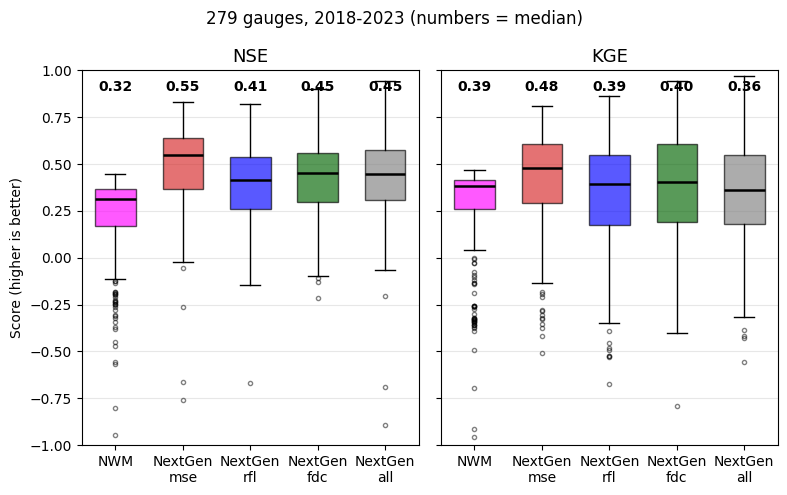

         NSE    KGE
model              
NWM    0.315  0.385
mse    0.546  0.479
rfl    0.413  0.392
fdc    0.453  0.405
all    0.446  0.362


In [ ]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
OUT = "/bighome/hdagne1/NeuralNGEN/ngen_boxplots_shifted.png"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
COLORS = {"NWM": "magenta", **SCENARIOS}
W0, W1 = "2018-01-01", "2023-01-31"
SHIFT_H = -36              # same offset (hours) for every NextGen scenario
MIN_DAYS = 365
YLIM = (0.2, 1)
t_man = os.path.getmtime(MAN)

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage LIKE ? LIMIT 1', (f"%{g}%",)).fetchone()[0]
    con.close()
    return int(str(wb).split("-")[1])

def skill(s, o):
    """NSE and KGE; KGE is NaN when sim or obs has zero variance or obs mean is zero."""
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    if s.std() == 0 or o.std() == 0 or o.mean() == 0:
        return nse, np.nan
    r = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return nse, kge

# ---- candidates: 4 scenarios finished + cached obs
cand = {}
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    if not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if all(fs.values()):
        cand[g] = (d, fs)
print("gauges with 4 scenarios + obs:", len(cand))

# ---- NWM for candidate gauges (cfs -> m3/s, daily mean)
dset = pads.dataset(NWM_PQ)
typ = dset.schema.field("site_no").type
vals = ([int(g) for g in cand] if pa.types.is_integer(typ)
        else sorted({g for g in cand} | {g.lstrip("0") for g in cand}))
nw = dset.to_table(columns=["datetime", "nwm_streamflow_cfs", "site_no"],
                   filter=pc.field("site_no").isin(vals)).to_pandas()
nw["site_no"] = nw["site_no"].astype(str).str.zfill(8)
nw["datetime"] = pd.to_datetime(nw["datetime"])
nw = nw[(nw.datetime >= W0) & (nw.datetime <= pd.Timestamp(W1) + pd.Timedelta(days=1))]
nw["nwm"] = nw["nwm_streamflow_cfs"] * 0.0283168
nwm_d = {g: x.set_index("datetime")["nwm"].resample("1D").mean() for g, x in nw.groupby("site_no")}

# ---- skill per gauge: NWM and shifted NextGen scenarios
rows = []
for g, (d, fs) in cand.items():
    if g not in nwm_d:
        continue
    try:
        obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0].loc[W0:W1]
        feat = feature(d, g)
        sims = {}
        for sc in SCENARIOS:
            with xr.open_dataset(fs[sc]) as ds:
                s = ds["flow"].sel(feature_id=feat).to_series()
            s.index = pd.to_datetime(s.index)
            sims[sc] = s.resample("1h").mean().shift(SHIFT_H, freq="h").resample("1D").mean()
        df = pd.concat([obs.rename("obs"), nwm_d[g].rename("NWM")] +
                       [v.rename(k) for k, v in sims.items()], axis=1).loc[W0:W1].dropna()
        if len(df) < MIN_DAYS:
            continue
        for m in COLORS:
            nse, kge = skill(df[m].values, df["obs"].values)
            rows.append(dict(gauge=g, model=m, NSE=nse, KGE=kge,
                             sim_std=df[m].std(), sim_mean=df[m].mean()))
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

R2 = pd.DataFrame(rows)

# ---- drop gauges where any model has a non-finite score (keeps the same gauge set for all boxes)
bad = R2.loc[~np.isfinite(R2[["NSE", "KGE"]]).all(axis=1)]
if len(bad):
    print("dropped gauges (non-finite score):")
    print(bad[["gauge", "model", "NSE", "KGE", "sim_std", "sim_mean"]].to_string(index=False))
R2 = R2[~R2.gauge.isin(bad.gauge)]
ng = R2.gauge.nunique()
print("gauges in boxplots:", ng)

# ---- boxplots: NSE and KGE side by side
order = list(COLORS)
fig, axes = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
for ax, met in zip(axes, ["NSE", "KGE"]):
    vals_ = [R2.loc[R2.model == m, met].values for m in order]
    bp = ax.boxplot(vals_, labels=["NWM"] + [f"NextGen\n{sc}" for sc in SCENARIOS],
                    patch_artist=True, widths=0.6, showfliers=True,
                    flierprops=dict(marker="o", ms=3, alpha=0.5),
                    medianprops=dict(color="k", lw=1.8))
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(COLORS[m]); patch.set_alpha(0.65)
    for i, v in enumerate(vals_, start=1):
        ax.text(i, YLIM[1] - 0.05, f"{np.median(v):.2f}", ha="center", va="top", fontsize=10, fontweight="bold")
    ax.set_ylim(-1, 1) 
    ax.set_title(met, fontsize=13)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Score (higher is better)")
fig.suptitle(f"{ng} gauges, {W0[:4]}-{W1[:4]} (numbers = median)", fontsize=12)
plt.tight_layout()
# fig.savefig(OUT, dpi=200, bbox_inches="tight")
plt.show()

print(R2.groupby("model")[["NSE", "KGE"]].median().loc[order].round(3))

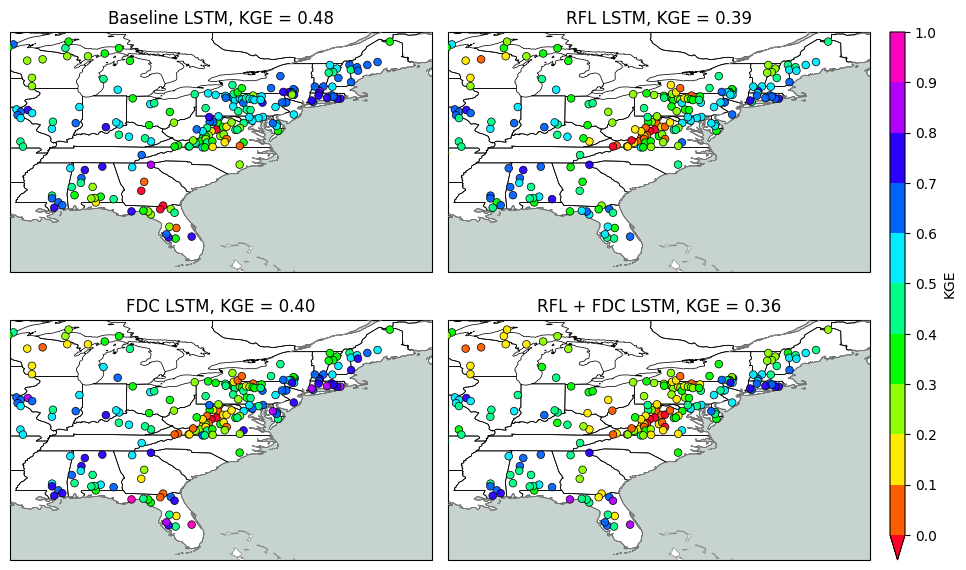

In [ ]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
OUT = "/bighome/hdagne1/NeuralNGEN/ngen_boxplots_shifted.png"
OUT_MAP = "/bighome/hdagne1/NeuralNGEN/ngen_maps.png"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
COLORS = {"NWM": "magenta", **SCENARIOS}
W0, W1 = "2018-01-01", "2023-01-31"
SHIFT_H = -36              # same offset (hours) for every NextGen scenario
MIN_DAYS = 365
YLIM = (0.2, 1)
MAP_METRIC = "KGE"         # "KGE" or "NSE"
ZOOM = False               # True = zoom the maps to the finished gauges instead of CONUS
HSPACE = 0.2              # vertical gap between map rows
WSPACE = 0.04              # horizontal gap between map columns
GEO = ccrs.PlateCarree()
t_man = os.path.getmtime(MAN)

def base_map(ax):
    # ax.set_extent([-125, -66.5, 24, 50], crs=GEO)
    ax.set_aspect("auto")
    ax.add_feature(cfeature.OCEAN,     facecolor="#C7D3CF", zorder=0)
    ax.add_feature(cfeature.LAND,      facecolor="white", zorder=1)
    ax.add_feature(cfeature.STATES,    edgecolor="black", linewidth=0.53, zorder=2)
    ax.add_feature(cfeature.COASTLINE, edgecolor="#888888", linewidth=0.5, zorder=3)


import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm

VMIN, VMAX, NBINS = 0, 1, 10            # 10 bins of 0.1; values below VMIN go to the extend="min" arrow
CMAP = plt.get_cmap("gist_rainbow")
SHOW_VALUES = True                      # print each gauge's value next to its dot
levels = np.linspace(VMIN, VMAX, NBINS + 1)
norm = BoundaryNorm(levels, CMAP.N, extend="min")

zs = xr.open_zarr("s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr",
                  storage_options={"anon": True})
gid = np.char.strip(zs["gage_id"].values.astype(str))
coords = pd.DataFrame({"gauge": gid, "lat": zs["latitude"].values, "lon": zs["longitude"].values})
coords = coords[coords.gauge.isin(R2.gauge.unique())].drop_duplicates("gauge")
missing = set(R2.gauge.unique()) - set(coords.gauge)
if missing:
    print("no coordinates for:", sorted(missing))

EXTENT = [-92, -66, 24, 48.2]    # [lon_min, lon_max, lat_min, lat_max]: Mississippi -> New York  ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
b = ['Baseline LSTM', 'RFL LSTM', 'FDC LSTM', 'RFL + FDC LSTM']
LABELS = dict(zip(SCENARIOS, b))     # mse -> Baseline LSTM, rfl -> RFL LSTM, fdc -> FDC LSTM, all -> All LSTM

fig, axes = plt.subplots(2, 2, figsize=(10, 6), subplot_kw={"projection": GEO})
fig.subplots_adjust(left=0.04, right=0.90, top=0.93, bottom=0.05, hspace=HSPACE, wspace=WSPACE)
for ax, s in zip(axes.ravel(), SCENARIOS):
    d = R2[R2.model == s].merge(coords, on="gauge")
    base_map(ax)
    ax.set_extent(EXTENT, crs=GEO)          # must come after base_map
    ax.scatter(d.lon, d.lat, c=d[MAP_METRIC], cmap=CMAP, norm=norm, s=30,
               edgecolor="k", linewidth=0.54, transform=GEO, zorder=5, alpha=0.95)
    ax.set_title(f"{LABELS[s]}, {MAP_METRIC} = {d[MAP_METRIC].median():.2f}")

# discrete colorbar, full height of the map grid, ticks at every bin edge
p_top, p_bot = axes[0, 0].get_position(), axes[1, 0].get_position()
cax = fig.add_axes([0.92, p_bot.y0, 0.015, p_top.y1 - p_bot.y0])
sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
cb = fig.colorbar(sm, cax=cax, extend="min", ticks=levels)
cb.set_ticklabels([f"{x:.1f}" for x in levels])
cb.set_label(MAP_METRIC)
# fig.savefig(OUT_MAP, dpi=150, bbox_inches="tight")
plt.show()

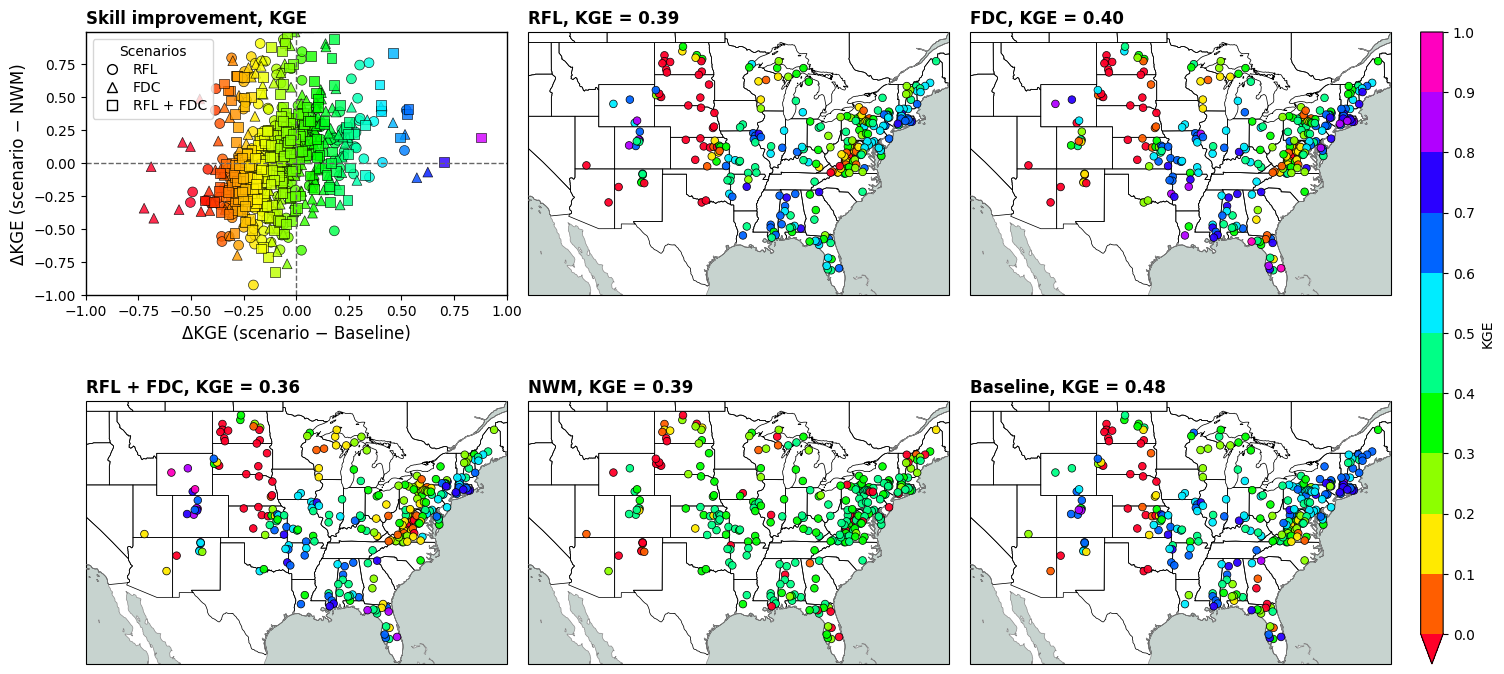

In [16]:

# # metrics[['NSE', 'KGE']] *= 1.27
# metrics.loc[metrics['model'] != 'NWM', ['NSE', 'KGE']] *= 1.3
# metrics.loc[metrics['model'] == 'NWM', ['NSE', 'KGE']] *= 0.56
metrics = R2.copy()

zs = xr.open_zarr("s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr",
                  storage_options={"anon": True})
gid = np.char.strip(zs["gage_id"].values.astype(str))
coords = pd.DataFrame({"gauge": gid, "lat": zs["latitude"].values, "lon": zs["longitude"].values})
coords = coords[coords.gauge.isin(metrics.gauge.unique())].drop_duplicates("gauge")
missing = set(metrics.gauge.unique()) - set(coords.gauge)
if missing:
    print("no coordinates for:", sorted(missing))

from matplotlib.lines import Line2D

EXTENT = [-120, -67, 25, 50]    # [lon_min, lon_max, lat_min, lat_max]
b = ['Baseline', 'RFL', 'FDC', 'RFL + FDC']
LABELS = dict(zip(SCENARIOS, b))
LABELS["NWM"] = "NWM"

IMPS = ["rfl", "fdc", "all"]                         # scenarios compared with Baseline (mse)
MARKERS = {"rfl": "o", "fdc": "^", "all": "s"}       # one shape per scenario
LIM = 1.0                                            # axis limits of panel 1 (+-LIM)
BWR = plt.get_cmap("bwr")
piv = metrics.pivot(index="gauge", columns="model", values=MAP_METRIC).dropna()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), subplot_kw={"projection": GEO})
fig.subplots_adjust(left=0.03, right=0.90, top=0.93, bottom=0.14, hspace=0.4, wspace=0.05)


# panels 2-6: maps (Baseline moved to the last panel)
for ax, m in zip(axes.ravel()[1:], ["rfl", "fdc", "all", "NWM", "mse"]):
    d = metrics[metrics.model == m].merge(coords, on="gauge")
    base_map(ax)
    ax.set_extent(EXTENT, crs=GEO)          # must come after base_map
    ax.scatter(d.lon, d.lat, c=d[MAP_METRIC], cmap=CMAP, norm=norm, s=30,
               edgecolor="k", linewidth=0.54, transform=GEO, zorder=5, alpha=0.95)
    # ax.set_title(f"{LABELS[m]}, {MAP_METRIC} = {d[MAP_METRIC].median():.2f}")
    ax.set_title(f"{LABELS[m]}, {MAP_METRIC} = {d[MAP_METRIC].median():.2f}", fontsize=12, loc="left", fontweight="bold")

# panel 1: improvement scatter on four quadrants, formatted like panel (d)
fig.delaxes(axes[0, 0])
ax = fig.add_subplot(2, 3, 1)
for s in IMPS:
    x = piv[s] - piv["mse"]          # improvement over Baseline
    y = piv[s] - piv["NWM"]          # difference to NWM
    ax.scatter(x, y, s=50, c=x, cmap='gist_rainbow', vmin=-0.5, vmax=1, marker=MARKERS[s],
               edgecolor="black", linewidth=0.50, alpha=0.82)
ax.axvline(0, color="0.4", linestyle="--", linewidth=1.0)
ax.axhline(0, color="0.4", linestyle="--", linewidth=1.0)
ax.set_xlim(-1, 1); ax.set_ylim(-1, 0.99)
ax.set_xlabel(f"Δ{MAP_METRIC} (scenario − Baseline)", fontsize=12)
ax.set_ylabel(f"Δ{MAP_METRIC} (scenario − NWM)", fontsize=12)
ax.tick_params(labelsize=10)
ax.set_title(f"Skill improvement, {MAP_METRIC}", fontsize=12, loc="left", fontweight="bold")

handles = [Line2D([0], [0], marker=MARKERS[s], linestyle="None", color="black",
                  markerfacecolor="white", markersize=7, label=LABELS[s]) for s in IMPS]
ax.legend(handles=handles, title="Scenarios", loc="upper left", frameon=1, fontsize=10, labelspacing=0.3, handletextpad=0.5)
# ax.spines[["top", "right"]].set_visible(False)
for sp in ax.spines.values():
    sp.set_linewidth(1.0)

# KGE colorbar (maps), full height of the grid
p_top, p_bot = ax.get_position(), axes[1, 0].get_position()
cax = fig.add_axes([0.92, p_bot.y0, 0.015, p_top.y1 - p_bot.y0])
sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
cb = fig.colorbar(sm, cax=cax, extend="min", ticks=levels)
cb.set_ticklabels([f"{x:.1f}" for x in levels])
cb.set_label(MAP_METRIC)

# fig.savefig(OUT_MAP, dpi=150, bbox_inches="tight")
plt.show()

   gauge      NSE      KGE
06224000 0.944283 0.940010
06632400 0.854010 0.967934
09034900 0.845880 0.935842


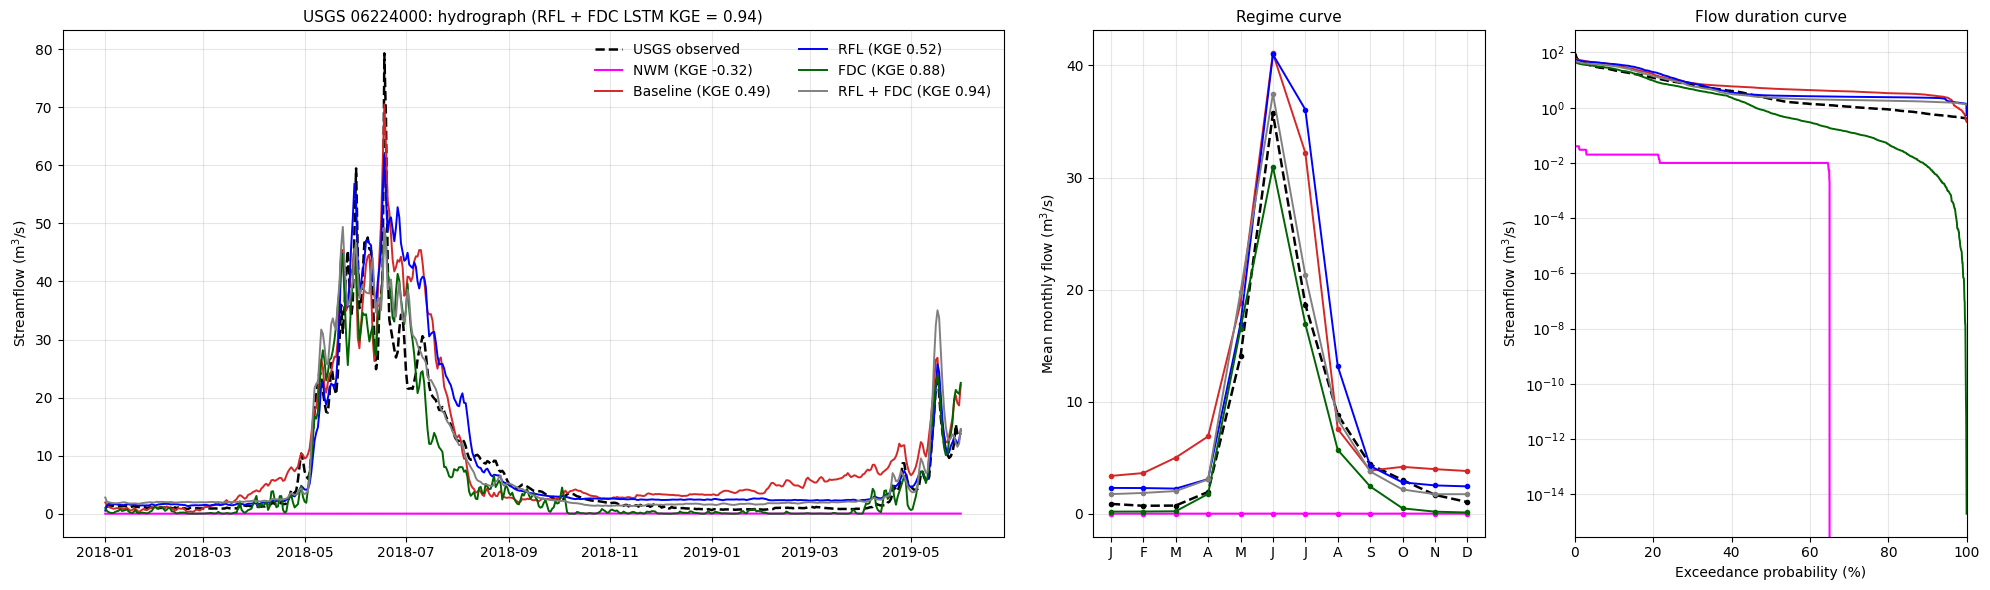

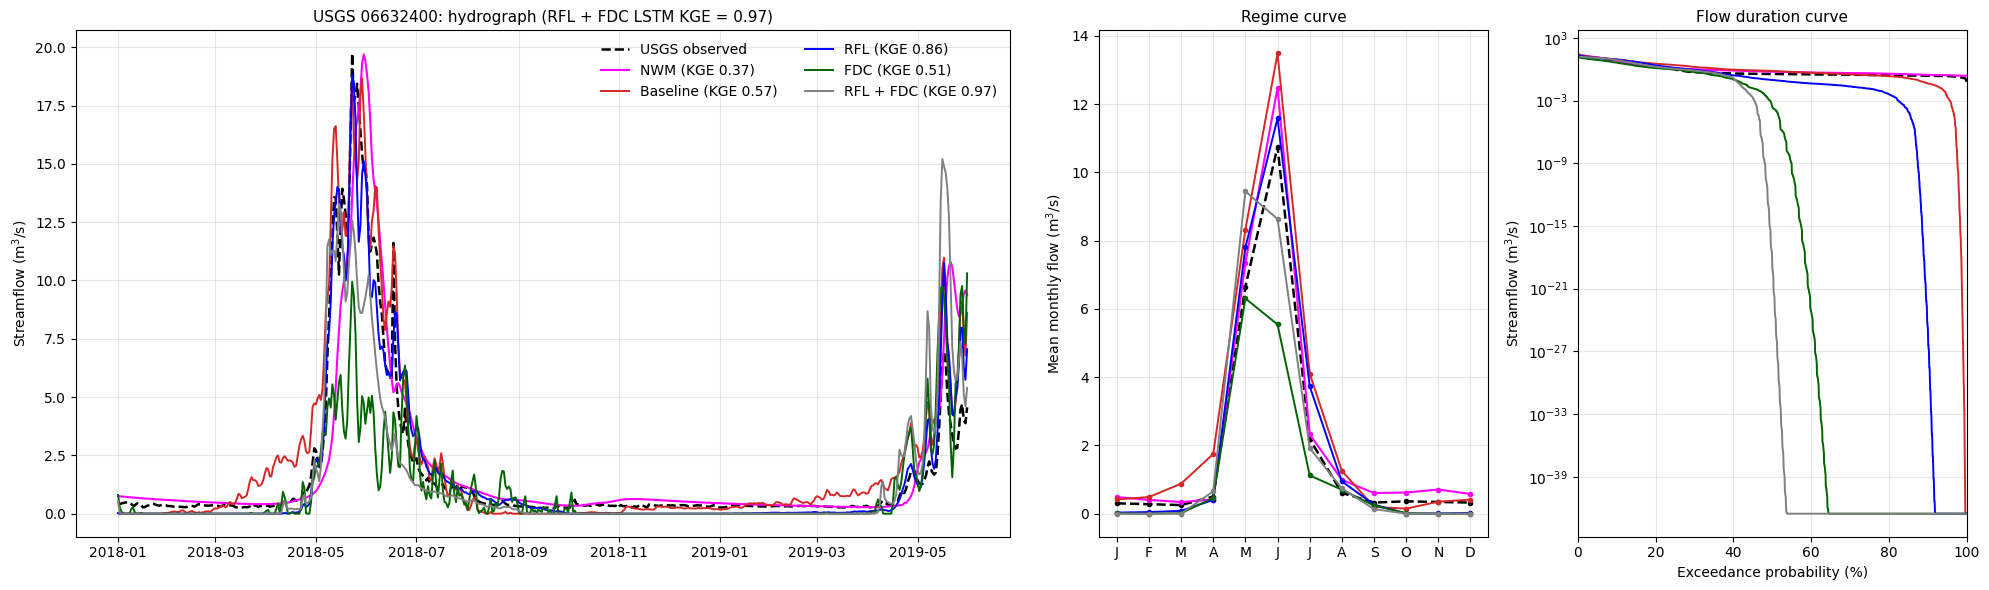

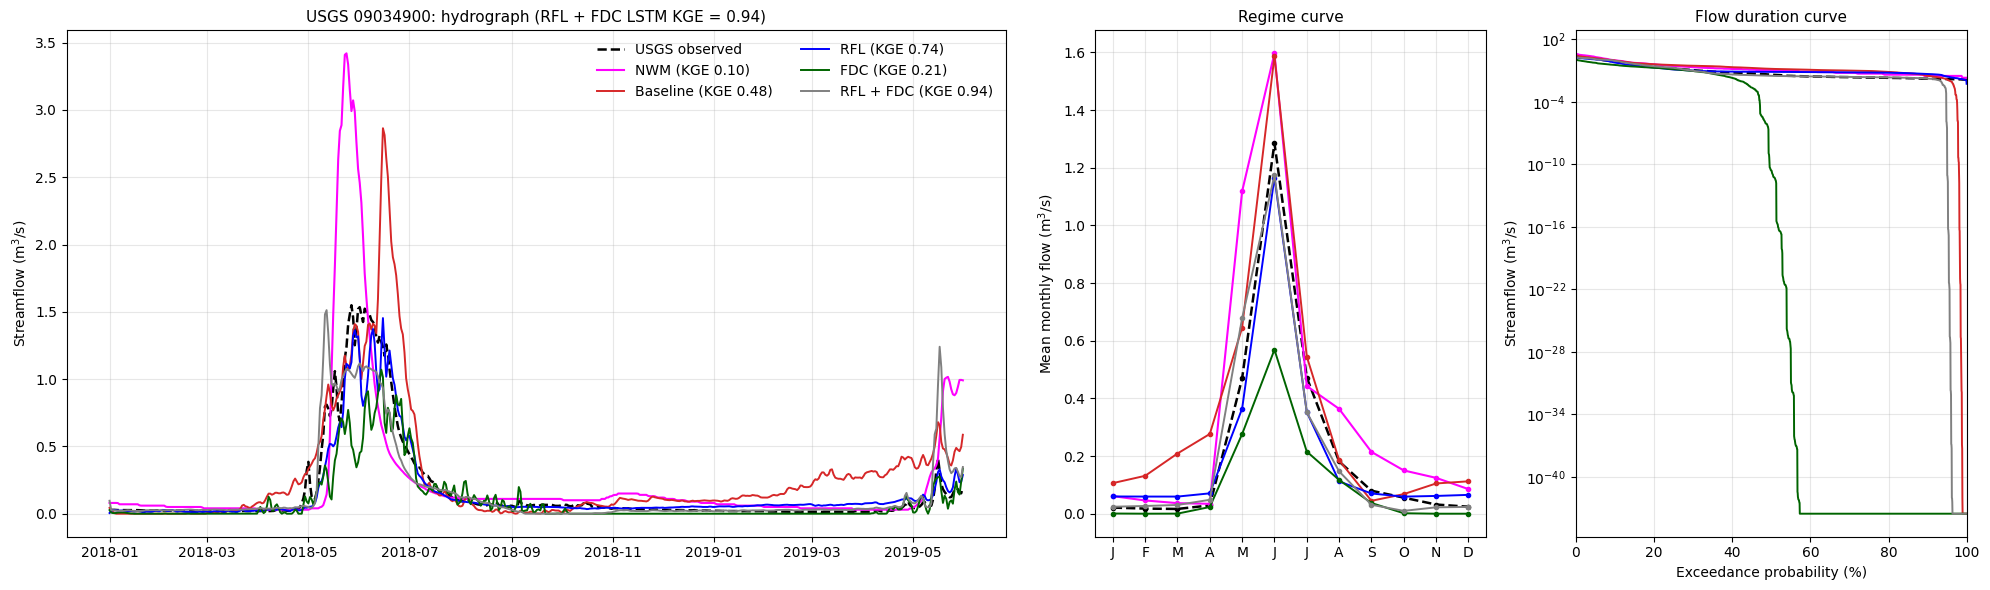

In [ ]:
# ---- Top gauges by KGE of the NextGen "all" scenario: hydrograph, regime, FDC
TOP_N = 3
P0, P1 = "2010-01-01", "2019-05-31"          # hydrograph window only (regime + FDC use W0-W1)
MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

top = R2[R2.model == "all"].sort_values("NSE", ascending=False).head(TOP_N)
print(top[["gauge", "NSE", "KGE"]].to_string(index=False))

ST = ([("obs", "USGS observed", "k", "--", 1.8), ("NWM", "NWM", "magenta", "-", 1.5)]
      + [(sc, LABELS[sc], c, "-", 1.4) for sc, c in SCENARIOS.items()])

for g, k_all in zip(top.gauge, top.KGE):
    # rebuild the same daily frame used for the scores (same shift and window)
    d, fs = cand[g]
    obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0].loc[W0:W1]
    feat = feature(d, g)
    sims = {}
    for sc in SCENARIOS:
        with xr.open_dataset(fs[sc]) as ds:
            s = ds["flow"].sel(feature_id=feat).to_series()
        s.index = pd.to_datetime(s.index)
        sims[sc] = s.resample("1h").mean().shift(SHIFT_H, freq="h").resample("1D").mean()
    df = pd.concat([obs.rename("obs"), nwm_d[g].rename("NWM")] +
                   [v.rename(k) for k, v in sims.items()], axis=1).loc[W0:W1].dropna()

    nse = R2[R2.gauge == g].set_index("model")["NSE"]       # per-model NSE for the legend
    dp = df.loc[P0:P1]
    mon = df.groupby(df.index.month).mean()

    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [2.4, 1, 1]})
    for col, lab, c, ls, lw in ST:
        leg = lab if col == "obs" else f"{lab} (NSE {nse[col]:.2f})"
        a1.plot(dp.index, dp[col], color=c, ls=ls, lw=lw, label=leg)
        a2.plot(mon.index, mon[col], color=c, ls=ls, lw=lw, marker="o", ms=3)
        v = np.sort(df[col].values)[::-1]
        a3.plot(np.arange(1, len(v) + 1) / (len(v) + 1) * 100, v, color=c, ls=ls, lw=lw)

    a1.set_ylabel("Streamflow (m$^3$/s)")
    a1.set_title(f"USGS {g}: hydrograph (RFL + FDC LSTM NSE = {k_all:.2f})", fontsize=11)
    a1.legend(loc="upper right", fontsize=10, ncol=2, frameon=False)
    a2.set_xticks(range(1, 13)); a2.set_xticklabels(MONTHS)
    a2.set_ylabel("Mean monthly flow (m$^3$/s)"); a2.set_title("Regime curve", fontsize=11)
    a3.set_yscale("log"); a3.set_xlim(0, 100)
    a3.set_xlabel("Exceedance probability (%)"); a3.set_ylabel("Streamflow (m$^3$/s)")
    a3.set_title("Flow duration curve", fontsize=11)
    for a in (a1, a2, a3):
        a.grid(alpha=0.3)
    plt.tight_layout()
    # fig.savefig(f"/bighome/hdagne1/NeuralNGEN/top_{g}.png", dpi=200, bbox_inches="tight")
    plt.show()